## Business Questions

1. What app characteristics (price, size, and platform compatibility) are associated with higher install volumes?

This question helps inform product-design and technical-scoping decisions — for example, whether to build a free or paid app, how large the app should be, and which Android versions to support at launch. Together, these are largely "build" decisions the company would make before development even starts.

2. Is there a relationship between user engagement (number of reviews) and app ratings?


This helps the company understand whether apps that generate more user engagement also tend to be better-rated — informing decisions around how much to invest in strategies that drive reviews/engagement (e.g., prompts, community building) as part of a broader quality or marketing strategy.

3. How do installs and ratings vary across different app categories or genres?


This is a market-selection question — it helps the company decide which category or genre to enter based on where demand (installs) and audience satisfaction (ratings) are strongest, and where the market may be saturated or underperforming.

4. Is content rating (audience maturity level) associated with differences in installs and ratings?


This informs audience-targeting decisions — whether designing for a broader audience (e.g., "Everyone") versus a narrower one (e.g., "Teen" or "Mature") is associated with better market performance, which affects both content design and marketing scope.



## Confirming the installation


## Start a Spark Session 

In [4]:

from pyspark.sql import SparkSession 

spark = SparkSession.builder \
    .appName("DataPrep") \
    .master("local[*]") \
    .getOrCreate()

print(f"Spark version {spark.version}")


Spark version 3.5.1


## Load and inspect the Data

### Load the dataset

In [5]:
# Load the dataset

df = spark.read.csv(
    "google_play_store_dataset.csv",
    header=True, #first row is column names 
    inferSchema=True, #Spark guesses datatypes
    sep=",", #delimeter (type of dataset-- change dataset is tab or ; delimeted)

)


In [6]:
# Verify the data loading

# Number of rows
row_count = df.count()
print(f"Number of rows: {row_count} \n")

# Number of columns and names 
print(f"Number of columns: {len(df.columns)}")
print(f"Column: {df.columns} \n")

df.show(5)

Number of rows: 10841 

Number of columns: 13
Column: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver'] 

+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+------------------+------------+
|                 App|      Category|Rating|Reviews|Size|   Installs|Type|Price|Content Rating|              Genres|    Last Updated|       Current Ver| Android Ver|
+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+------------------+------------+
|Photo Editor & Ca...|ART_AND_DESIGN|   4.1|    159| 19M|    10,000+|Free|    0|      Everyone|        Art & Design| January 7, 2018|             1.0.0|4.0.3 and up|
| Coloring book moana|ART_AND_DESIGN|   3.9|    967| 14M|   500,000+|Free|    0|      Everyone|Art & Design;Pret...|January 15, 

### Inspect the Data 

**Descriptive analysis for all columns**

In [7]:
# Schema: column names and inferred data types
df.printSchema()

# Summary stats: count, mean, stddev, min, max 
# --checks for numeric/string columns
df.describe().show()


root
 |-- App: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: string (nullable = true)
 |-- Reviews: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Installs: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Genres: string (nullable = true)
 |-- Last Updated: string (nullable = true)
 |-- Current Ver: string (nullable = true)
 |-- Android Ver: string (nullable = true)

+-------+--------------------+-------------+-----------+-----------------+------------------+------------------+-----+------------------+--------------+------+-----------------+-------------+------------------+
|summary|                 App|     Category|     Rating|          Reviews|              Size|          Installs| Type|             Price|Content Rating|Genres|     Last Updated|  Current Ver|       Android Ver|
+-------+--------------------+-------------+-----------+-

* *Finding: Category's mean should not be a numerical value*
* *The numerical data i.e reviews, size, installs,price*

**Potential anomalies**

In [8]:
# Check for the corrupted row 
df.filter(df.Category == "1.9").show()

+--------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|                 App|Category|Rating|Reviews|  Size|Installs|Type|   Price|Content Rating|           Genres|Last Updated|Current Ver|Android Ver|
+--------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+
|Life Made WI-Fi T...|     1.9|    19|   3.0M|1,000+|    Free|   0|Everyone|          NULL|February 11, 2018|      1.0.19| 4.0 and up|       NULL|
+--------------------+--------+------+-------+------+--------+----+--------+--------------+-----------------+------------+-----------+-----------+



*finding: the value for category is missing and everything after that has been pushed back thus the 1.9 is the actual value for rating*

*verdict: remove the entire row*

In [9]:
# Remove the corrupted row
df_clean = df.filter(df.Category != "1.9")

# Confirm the row count dropped by exactly 1
print("Before:", df.count())
print("After:", df_clean.count())

Before: 10841
After: 10840


In [10]:
# Check the cateogory column to confirm it's analysis is correct
df_clean.describe().show()

+-------+--------------------+-------------+-----------+-----------------+------------------+------------------+------+------------------+--------------+------+-----------------+-------------+------------------+
|summary|                 App|     Category|     Rating|          Reviews|              Size|          Installs|  Type|             Price|Content Rating|Genres|     Last Updated|  Current Ver|       Android Ver|
+-------+--------------------+-------------+-----------+-----------------+------------------+------------------+------+------------------+--------------+------+-----------------+-------------+------------------+
|  count|               10840|        10840|      10840|            10840|             10840|             10840| 10840|             10840|         10840| 10840|            10840|        10839|             10840|
|   mean|                NULL|         NULL|        NaN|444225.1924709356|              NULL| 2.866666666666667|   NaN|               0.0|          NULL

**Numerical data analysis**

* Convert Reviews/Size/Installs/Price to numerical data
* Complete the analysis for the columns 



In [11]:
# Reviews 
df_clean = df_clean.withColumn("Reviews_num", df_clean["Reviews"].cast("int"))
df_clean.select("Reviews", "Reviews_num").show(5)

+-------+-----------+
|Reviews|Reviews_num|
+-------+-----------+
|    159|        159|
|    967|        967|
|  87510|      87510|
| 215644|     215644|
|    967|        967|
+-------+-----------+
only showing top 5 rows



In [12]:
# Price
from pyspark.sql.functions import regexp_replace

df_clean = df_clean.withColumn(
    "Price_num",
    regexp_replace(df_clean["Price"], "\\$", "").cast("double")
)
df_clean.select("Price", "Price_num").show(5)

+-----+---------+
|Price|Price_num|
+-----+---------+
|    0|      0.0|
|    0|      0.0|
|    0|      0.0|
|    0|      0.0|
|    0|      0.0|
+-----+---------+
only showing top 5 rows



In [13]:
# Installs
df_clean = df_clean.withColumn(
    "Installs_num",
    regexp_replace(regexp_replace(df_clean["Installs"], ",", ""), "\\+", "").cast("long")
)
df_clean.select("Installs", "Installs_num").show(5)

+-----------+------------+
|   Installs|Installs_num|
+-----------+------------+
|    10,000+|       10000|
|   500,000+|      500000|
| 5,000,000+|     5000000|
|50,000,000+|    50000000|
|   100,000+|      100000|
+-----------+------------+
only showing top 5 rows



In [14]:
# Size
df_clean = df_clean.withColumn(
    "Size_num",
    regexp_replace(df_clean["Size"], "M", "").cast("double")
)
df_clean.select("Size", "Size_num").show(10)

+----+--------+
|Size|Size_num|
+----+--------+
| 19M|    19.0|
| 14M|    14.0|
|8.7M|     8.7|
| 25M|    25.0|
|2.8M|     2.8|
|5.6M|     5.6|
| 19M|    19.0|
| 29M|    29.0|
| 33M|    33.0|
|3.1M|     3.1|
+----+--------+
only showing top 10 rows



**Descriptive column analysis (using converted data)**



In [15]:
df_clean.select("Rating", "Reviews_num", "Price_num", "Installs_num", "Size_num").describe().show()

+-------+-----------+-----------------+------------------+--------------------+------------------+
|summary|     Rating|      Reviews_num|         Price_num|        Installs_num|          Size_num|
+-------+-----------+-----------------+------------------+--------------------+------------------+
|  count|      10840|            10838|             10838|               10840|              8828|
|   mean|        NaN|444225.1924709356|1.0275576674663114|1.5463785377767527E7|22.272496601721688|
| stddev|        NaN|2928025.838407947|15.951169076625343| 8.502944796374594E7| 22.62922635380135|
|    min| navigation|                0|               0.0|                   0|               1.0|
|    max|        NaN|         78158306|             400.0|          1000000000|             100.0|
+-------+-----------+-----------------+------------------+--------------------+------------------+



In [16]:
#  Rating distribution - see how ratings are spread out (and spot missing/null ratings)
df_clean.groupBy("Rating").count().orderBy("Rating").show(50)



+-----------+-----+
|     Rating|count|
+-----------+-----+
| navigation|    1|
|        1.0|   16|
|        1.2|    1|
|        1.4|    3|
|        1.5|    3|
|        1.6|    4|
|        1.7|    8|
|        1.8|    8|
|        1.9|   13|
|        2.0|   12|
|        2.1|    8|
|        2.2|   14|
|        2.3|   20|
|        2.4|   19|
|        2.5|   21|
|        2.6|   25|
|        2.7|   25|
|        2.8|   42|
|        2.9|   45|
|        3.0|   83|
|        3.1|   69|
|        3.2|   64|
|        3.3|  102|
|        3.4|  128|
|        3.5|  163|
|        3.6|  174|
|        3.7|  239|
|        3.8|  303|
|        3.9|  386|
|        4.0|  568|
|        4.1|  708|
|        4.2|  951|
|        4.3| 1076|
|        4.4| 1108|
|        4.5| 1038|
|        4.6|  823|
|        4.7|  499|
|        4.8|  234|
|        4.9|   87|
|        5.0|  274|
|       Body|    1|
|        NaN| 1474|
+-----------+-----+



*finding: most of the apps are rated 1.9 and above*

In [17]:
#  Type (Free vs Paid) - simple counts to check for unexpected values
df_clean.groupBy("Type").count().show()



+------+-----+
|  Type|count|
+------+-----+
|102248|    1|
|   NaN|    1|
|  Free|10037|
|  Paid|  800|
|  2509|    1|
+------+-----+



*finding: most of the apps are free*

In [18]:
#  Content Rating - see which audience categories are most common
df_clean.groupBy("Content Rating").count().orderBy("count", ascending=False).show()

+---------------+-----+
| Content Rating|count|
+---------------+-----+
|       Everyone| 8713|
|           Teen| 1208|
|     Mature 17+|  498|
|   Everyone 10+|  414|
|Adults only 18+|    3|
|        Unrated|    2|
|     5,000,000+|    1|
|     1,000,000+|    1|
+---------------+-----+



*The biggest niche is the teens section while majority of the apps are made for everyone*

In [19]:
# Category --see which categories are the most common/ popular
df_clean.groupBy("Category").count().orderBy("count", ascending=False).show(35)

+-------------------+-----+
|           Category|count|
+-------------------+-----+
|             FAMILY| 1972|
|               GAME| 1144|
|              TOOLS|  843|
|            MEDICAL|  463|
|           BUSINESS|  460|
|       PRODUCTIVITY|  424|
|    PERSONALIZATION|  392|
|      COMMUNICATION|  387|
|             SPORTS|  384|
|          LIFESTYLE|  382|
|            FINANCE|  366|
| HEALTH_AND_FITNESS|  340|
|        PHOTOGRAPHY|  335|
|             SOCIAL|  295|
| NEWS_AND_MAGAZINES|  283|
|           SHOPPING|  260|
|   TRAVEL_AND_LOCAL|  258|
|             DATING|  234|
|BOOKS_AND_REFERENCE|  231|
|      VIDEO_PLAYERS|  175|
|          EDUCATION|  156|
|      ENTERTAINMENT|  149|
|MAPS_AND_NAVIGATION|  136|
|     FOOD_AND_DRINK|  127|
|     HOUSE_AND_HOME|   88|
|  AUTO_AND_VEHICLES|   85|
| LIBRARIES_AND_DEMO|   85|
|            WEATHER|   82|
|     ART_AND_DESIGN|   65|
|             EVENTS|   64|
|             COMICS|   60|
|          PARENTING|   60|
|             BEAUTY

*Family and Games categories hold a major share of the market*

6. Check for anomalies 

In [20]:
# Price outliers
df_clean.select("App", "Price_num").orderBy("Price_num", ascending=False).show(10)

+--------------------+---------+
|                 App|Price_num|
+--------------------+---------+
|I'm Rich - Trump ...|    400.0|
|           I am Rich|   399.99|
|most expensive ap...|   399.99|
|          I am Rich!|   399.99|
|         💎 I'm rich|   399.99|
|  I am rich(premium)|   399.99|
|           I am rich|   399.99|
|       I Am Rich Pro|   399.99|
|   I Am Rich Premium|   399.99|
|I am rich (Most e...|   399.99|
+--------------------+---------+
only showing top 10 rows



*The most expensive app goes for 400 and seems to be variations of each other*

In [21]:
# Installs outliers
df_clean.select("App", "Installs_num").orderBy("Installs_num", ascending=False).show(10)

+--------------------+------------+
|                 App|Installs_num|
+--------------------+------------+
|               Gmail|  1000000000|
|   Google Play Books|  1000000000|
|Messenger – Text ...|  1000000000|
|  WhatsApp Messenger|  1000000000|
|Google Chrome: Fa...|  1000000000|
|            Hangouts|  1000000000|
|  WhatsApp Messenger|  1000000000|
|Messenger – Text ...|  1000000000|
|            Hangouts|  1000000000|
|Skype - free IM &...|  1000000000|
+--------------------+------------+
only showing top 10 rows



*The most installed apps are majorly applications that foster communication be it casual or formal*

In [22]:
# size anomalies
df_clean.select("App", "Size_num").orderBy("Size_num", ascending=False).show(10)

+--------------------+--------+
|                 App|Size_num|
+--------------------+--------+
|Navi Radiography Pro|   100.0|
|Stickman Legends:...|   100.0|
|Hungry Shark Evol...|   100.0|
|Hungry Shark Evol...|   100.0|
|          Vi Trainer|   100.0|
|Hungry Shark Evol...|   100.0|
|     Ultimate Tennis|   100.0|
|Miami crime simul...|   100.0|
|Gangster Town: Vi...|   100.0|
|Mini Golf King - ...|   100.0|
+--------------------+--------+
only showing top 10 rows



*The largest apps are 100MB and seem to be gaming apps*

In [23]:
# apps with 0 reviews but high ratings 
df_clean.filter((df_clean["Reviews_num"] == 0) & (df_clean["Rating"] > 4)).select("App", "Rating", "Reviews_num").show(10)

+---+------+-----------+
|App|Rating|Reviews_num|
+---+------+-----------+
+---+------+-----------+



*Ever app that has a rating has a review*

## Data quality assessment tests 


### Check for missing values

In [24]:
from pyspark.sql.functions import col, count, when

total_rows = df_clean.count()

# Count actual number of missing (null) values per column
missing_counts = df_clean.select([
    count(when(col(c).isNull(), c)).alias(c) for c in df_clean.columns
])

# Count percentage of missing values per column
missing_percent = df_clean.select([
    (count(when(col(c).isNull(), c)) / total_rows * 100).alias(c) for c in df_clean.columns
])

print("Missing value COUNTS per column:")
missing_counts.show()

print("Missing value PERCENTAGES per column:")
missing_percent.show()

Missing value COUNTS per column:
+---+--------+------+-------+----+--------+----+-----+--------------+------+------------+-----------+-----------+-----------+---------+------------+--------+
|App|Category|Rating|Reviews|Size|Installs|Type|Price|Content Rating|Genres|Last Updated|Current Ver|Android Ver|Reviews_num|Price_num|Installs_num|Size_num|
+---+--------+------+-------+----+--------+----+-----+--------------+------+------------+-----------+-----------+-----------+---------+------------+--------+
|  0|       0|     0|      0|   0|       0|   0|    0|             0|     0|           0|          1|          0|          2|        2|           0|    2012|
+---+--------+------+-------+----+--------+----+-----+--------------+------+------------+-----------+-----------+-----------+---------+------------+--------+

Missing value PERCENTAGES per column:
+---+--------+------+-------+----+--------+----+-----+--------------+------+------------+-------------------+-----------+-----------------

*Most columns have zero or negligible null values apart from size which has 18% of it's data missing*

**Handling null values**

In [25]:
# Current Version column
df_clean = df_clean.fillna({"Current Ver": "Unknown"})

In [26]:
# Reviews and  Price columns 
# Show original values where the number conversion failed
df_clean.filter(col("Reviews_num").isNull()).select("App", "Reviews").show()
df_clean.filter(col("Price_num").isNull()).select("App", "Price").show()

+--------------------+-------------+
|                 App|      Reviews|
+--------------------+-------------+
|"Yanosik: ""antyr...|      camera"|
|"Women""s Health ...|weight lose)"|
+--------------------+-------------+

+--------------------+------------------+
|                 App|             Price|
+--------------------+------------------+
|"Yanosik: ""antyr...|Varies with device|
|"Women""s Health ...|              5.0M|
+--------------------+------------------+



*finding: The reviews and prices marked as null failed to convert because they had a similar anomaly as the category value handled before, the values after them have been pushed forward*

*verdict: drop the rows*

In [27]:
# Drop rows where Reviews_num or Price_num failed to convert (these are the corrupted rows)
df_clean = df_clean.filter(col("Reviews_num").isNotNull() & col("Price_num").isNotNull())

# Confirm the row count dropped by 2
df_clean.count()

10838

In [28]:
# Size
# See what original Size values are causing the nulls
df_clean.filter(col("Size_num").isNull()).groupBy("Size").count().orderBy(col("count").desc()).show(10)

+------------------+-----+
|              Size|count|
+------------------+-----+
|Varies with device| 1694|
|              118k|    3|
|              375k|    3|
|               79k|    3|
|              266k|    3|
|              201k|    3|
|              704k|    2|
|               33k|    2|
|              141k|    2|
|              206k|    2|
+------------------+-----+
only showing top 10 rows



* *finding: most of the sizes were in both MB and KB, in our initial conversion we converted those that were tagged with an M for MB and treated the K for KB as null*
* *finding: the bulk of the missing values are also those with indefinite thus the varies with device*

*Verdict: standardize the values of KB values to MB and as for the varies with device we leave them as such as they contribute to a major share of the data, about 10+%*

In [29]:
# Standardize the KB  values to MB and convert them to doubles 
from pyspark.sql.functions import when, regexp_replace, col

df_clean = df_clean.withColumn(
    "Size_num",
    when(col("Size").endswith("M"), regexp_replace(col("Size"), "M", "").cast("double"))
    .when(col("Size").endswith("k"), regexp_replace(col("Size"), "k", "").cast("double") / 1024)  # KB -> MB
    .otherwise(None)  # "Varies with device" stays null - it's not really missing, just unknown/variable
)

# Recheck missing count after the fix
df_clean.filter(col("Size_num").isNull()).count()

1694

**Check for duplicates**

In [30]:
# 1. Check for fully duplicate rows (every column identical)
full_dupes = df_clean.count() - df_clean.dropDuplicates().count()
print("Fully duplicate rows:", full_dupes)

# 2. Check for duplicate App names (same app listed more than once, even if other columns differ)
df_clean.groupBy("App").count().filter(col("count") > 1).orderBy(col("count").desc()).show(10)

Fully duplicate rows: 483
+--------------------+-----+
|                 App|count|
+--------------------+-----+
|              ROBLOX|    9|
|CBS Sports App - ...|    8|
|                ESPN|    7|
|         8 Ball Pool|    7|
|    Candy Crush Saga|    7|
|Duolingo: Learn L...|    7|
|Bleacher Report: ...|    6|
|      Bubble Shooter|    6|
|                Nick|    6|
|Sniper 3D Gun Sho...|    6|
+--------------------+-----+
only showing top 10 rows



*finding: There are 483 fully duplicated rows and several others that have the app name duplicated*

*Remove the fully duplicated rows and as for the duplicated app names keep only those that have the highest review counts as they denote the most successful version of the app*

In [31]:
# Remove fully identical duplicate rows, keep one copy of each
df_clean = df_clean.dropDuplicates()

print("Row count after removing exact duplicates:", df_clean.count())

Row count after removing exact duplicates: 10355


In [32]:
from pyspark.sql import Window
from pyspark.sql.functions import row_number, desc

# Rank duplicate App entries by Reviews_num (highest first) within each App name
window_spec = Window.partitionBy("App").orderBy(desc("Reviews_num"))

df_clean = df_clean.withColumn("row_num", row_number().over(window_spec))

# Keep only the top-ranked (most-reviewed) row per App
df_clean = df_clean.filter(col("row_num") == 1).drop("row_num")

print("Row count after removing App-name duplicates:", df_clean.count())

Row count after removing App-name duplicates: 9657


**Data quality assessment check**

In [33]:
# Check for casing/spacing inconsistencies in key text columns
df_clean.groupBy("Type").count().show()
df_clean.groupBy("Content Rating").count().show()

+----+-----+
|Type|count|
+----+-----+
| NaN|    1|
|Free| 8902|
|Paid|  754|
+----+-----+

+---------------+-----+
| Content Rating|count|
+---------------+-----+
|        Unrated|    2|
|           Teen| 1036|
|     Mature 17+|  392|
|   Everyone 10+|  322|
|       Everyone| 7902|
|Adults only 18+|    3|
+---------------+-----+



In [34]:
# Investigate the row where Type is "NaN"
df_clean.filter(col("Type") == "NaN").show()

+--------------------+--------+------+-------+------------------+--------+----+-----+--------------+--------+-------------+------------------+------------------+-----------+---------+------------+--------+
|                 App|Category|Rating|Reviews|              Size|Installs|Type|Price|Content Rating|  Genres| Last Updated|       Current Ver|       Android Ver|Reviews_num|Price_num|Installs_num|Size_num|
+--------------------+--------+------+-------+------------------+--------+----+-----+--------------+--------+-------------+------------------+------------------+-----------+---------+------------+--------+
|Command & Conquer...|  FAMILY|   NaN|      0|Varies with device|       0| NaN|    0|  Everyone 10+|Strategy|June 28, 2018|Varies with device|Varies with device|          0|      0.0|           0|    NULL|
+--------------------+--------+------+-------+------------------+--------+----+-----+--------------+--------+-------------+------------------+------------------+-----------+---

* *finding: a relatively new app with no engagement yet, it's an extreme edge case.* 
* *Since the price is 0 we'll safely asssume it's a free app*

In [35]:
# Fix the one row where Type is "NaN" - Price is 0, so it's safe to assume Free
df_clean = df_clean.withColumn(
    "Type",
    when((col("Type") == "NaN") & (col("Price_num") == 0), "Free").otherwise(col("Type"))
)

# Confirm the fix
df_clean.filter(col("Type") == "NaN").count()

0

In [36]:
# Count unique values per column to understand cardinality
for c in df_clean.columns:
    n_unique = df_clean.select(c).distinct().count()
    print(f"{c}: {n_unique} unique values")

App: 9657 unique values
Category: 33 unique values
Rating: 40 unique values
Reviews: 5332 unique values
Size: 461 unique values
Installs: 21 unique values
Type: 2 unique values
Price: 92 unique values
Content Rating: 6 unique values
Genres: 118 unique values
Last Updated: 1377 unique values
Current Ver: 2821 unique values
Android Ver: 34 unique values
Reviews_num: 5332 unique values
Price_num: 92 unique values
Installs_num: 20 unique values
Size_num: 460 unique values


**What I found and fixed:** *I started with 10,841 rows and found a handful of one-off corrupted rows — one where a missing Category value shifted every column left, and two more where quote marks in App names broke the CSV parsing. I dropped all three. I also found 483 exact duplicate rows, plus several popular apps (ROBLOX, ESPN, Candy Crush Saga) listed multiple times with different data, likely from being scraped on different dates — for those I kept only the version with the most reviews.*

**Type conversions:** Reviews, Size, Installs, and Price all came in as text instead of numbers, so I converted each one. Size proved to have the biggest challenge— 18.56% came back missing after conversion, but I traced that to mostly "Varies with device" entries (which I left as null on purpose, since that's a real value not a gap) plus some kilobyte values I hadn't converted yet which I then did.

**Small fixes:** I found one row with a missing Current Ver (filled it with "Unknown"), and one with an invalid "NaN" Type value (set it to "Free" since its Price was 0).



**Validation framework**

In [37]:
# 1. No more nulls in columns we fixed (Current Ver, Type)
print("Nulls in Current Ver:", df_clean.filter(col("Current Ver").isNull()).count())
print("Invalid Type values:", df_clean.filter(col("Type") == "NaN").count())

# 2. No exact duplicate rows remain
print("Exact duplicate rows:", df_clean.count() - df_clean.dropDuplicates().count())

# 3. No duplicate App names remain
print("Apps still duplicated:", df_clean.groupBy("App").count().filter(col("count") > 1).count())

# 4. Numeric columns are actually numeric now
df_clean.select("Reviews_num", "Price_num", "Installs_num", "Size_num").dtypes

# 5. Sanity check on ranges (nothing negative, ratings within 1-5)
print("Negative reviews:", df_clean.filter(col("Reviews_num") < 0).count())
print("Negative prices:", df_clean.filter(col("Price_num") < 0).count())
print("Ratings out of 1-5 range:", df_clean.filter((col("Rating") < 1) | (col("Rating") > 5)).count())

Nulls in Current Ver: 0
Invalid Type values: 0
Exact duplicate rows: 0
Apps still duplicated: 0
Negative reviews: 0
Negative prices: 0
Ratings out of 1-5 range: 0


## Export 


In [38]:
# pandas_df = df_clean.toPandas()

# pandas_df.to_csv("google_play_store_cleaned.csv", index=False)

# print("Export complete. Rows:", len(pandas_df), "| Columns:", len(pandas_df.columns))

## Initial visualization exploration

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert cleaned Spark data to Pandas once - small enough dataset, easy to plot from here
pdf = df_clean.toPandas()

print(pdf.shape)

(9657, 17)


**FREE VS PAID**

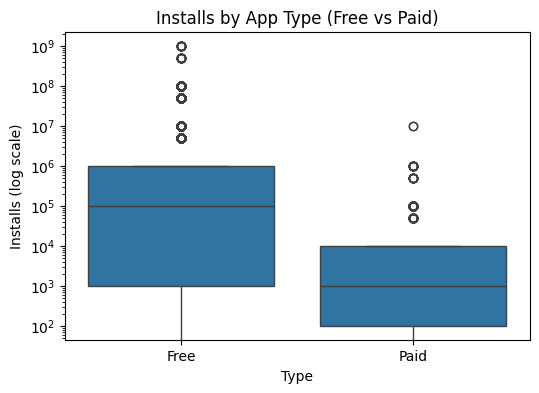

In [ ]:
# 
plt.figure(figsize=(6,4))
sns.boxplot(data=pdf, x="Type", y="Installs_num")
plt.yscale("log")  # installs are heavily skewed - log scale keeps this readable
plt.title("Installs by App Type (Free vs Paid)")
plt.ylabel("Installs (log scale)")
plt.show()

**APP SIZE VS INSTALLS**

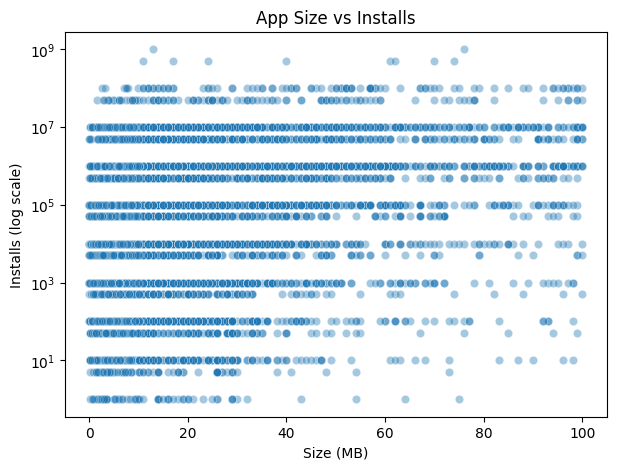

In [44]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=pdf, x="Size_num", y="Installs_num", alpha=0.4)
plt.yscale("log")  # same skew issue as before
plt.title("App Size vs Installs")
plt.xlabel("Size (MB)")
plt.ylabel("Installs (log scale)")
plt.show()

**REVIEWS VS RATINGS**

**CATEGORY VS AVERAGE INSTALS**

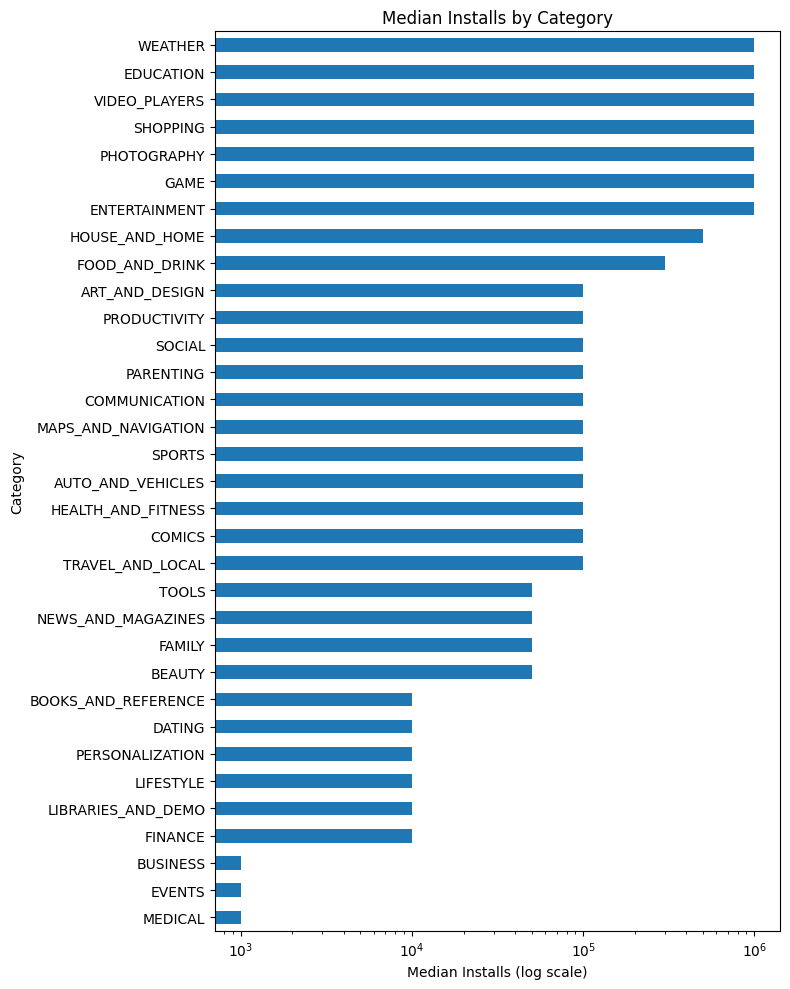

In [47]:
# Group by Category, calculate median installs (median chosen over average due to heavy skew), sort descending
category_installs = pdf.groupby("Category")["Installs_num"].median().sort_values(ascending=False)

plt.figure(figsize=(8,10))
category_installs.plot(kind="barh")
plt.xscale("log")  # installs are heavily skewed - log scale keeps this readable
plt.title("Median Installs by Category")
plt.xlabel("Median Installs (log scale)")
plt.ylabel("Category")
plt.gca().invert_yaxis()  # highest category on top
plt.tight_layout()
plt.show()